# 5. Évaluation, seuil et coût

Le seuil d'alerte est choisi sur la validation en minimisant un coût métier : somme des montants des fraudes manquées et d'un coût d'analyse de 5 par alerte.
Il est ensuite appliqué tel quel au test.

In [1]:
import sys
from pathlib import Path

RACINE = Path.cwd().resolve().parent
if str(RACINE) not in sys.path:
    sys.path.insert(0, str(RACINE))

import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore", message="IProgress not found")
pd.options.display.float_format = "{:,.4f}".format
pd.options.display.max_columns = 30
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})

BLEU = "#2a78d6"
ORANGE = "#eb6834"
VERT = "#1baf7a"
JAUNE = "#eda100"
ROSE = "#e87ba4"

In [2]:
from src import evaluation, metriques

jeux = evaluation.charger_scores(RACINE / "donnees")
COUT_ALERTE = evaluation.COUT_ALERTE
ALERTES_PAR_JOUR = evaluation.ALERTES_PAR_JOUR
{"cout_alerte": COUT_ALERTE, "alertes_par_jour": ALERTES_PAR_JOUR}

{'cout_alerte': 5.0, 'alertes_par_jour': 20.0}

## Budget d'alertes

Le budget k est exprimé en alertes par jour. La valeur par défaut, 20 par jour, vaut environ 1,5 fois le nombre moyen de fraudes par jour en validation (1 901 fraudes sur 140 jours, soit 13,6 par jour) : assez pour retrouver la plupart des fraudes malgré des fausses alertes. La précision@k et le rappel@k sont calculés sur les k transactions les mieux classées, k étant le budget par jour multiplié par le nombre de jours de la période.

In [3]:
validation, test = jeux["validation"], jeux["test"]
{
    "jours_validation": (validation["trans_date_trans_time"].max() - validation["trans_date_trans_time"].min()).days + 1,
    "k_validation": evaluation.budget(validation, ALERTES_PAR_JOUR),
    "k_test": evaluation.budget(test, ALERTES_PAR_JOUR),
    "fraudes_validation": int(validation["is_fraud"].sum()),
    "fraudes_test": int(test["is_fraud"].sum()),
}

{'jours_validation': 140,
 'k_validation': 2795,
 'k_test': 2579,
 'fraudes_validation': 1901,
 'fraudes_test': 1349}

## Seuil optimal sur la validation

In [4]:
choix = evaluation.seuil_optimal_validation(jeux, "xgboost")
choix

{'seuil': 0.027218025359384283,
 'alertes': 3763,
 'cout': 30109.10999999859,
 'cout_sans_modele': 989313.46}

In [5]:
courbe = evaluation.courbe_cout_selon_alertes(validation, "xgboost")
courbe.head()

,seuil,alertes,cout,alertes_par_jour
0,0.9998,0,"989,313.4600",0.0000
1,0.9998,1,"988,340.0400",0.0072
2,0.9995,2,"988,335.5600",0.0143
3,0.9995,4,"987,418.8300",0.0286
4,0.9995,5,"986,361.9200",0.0358


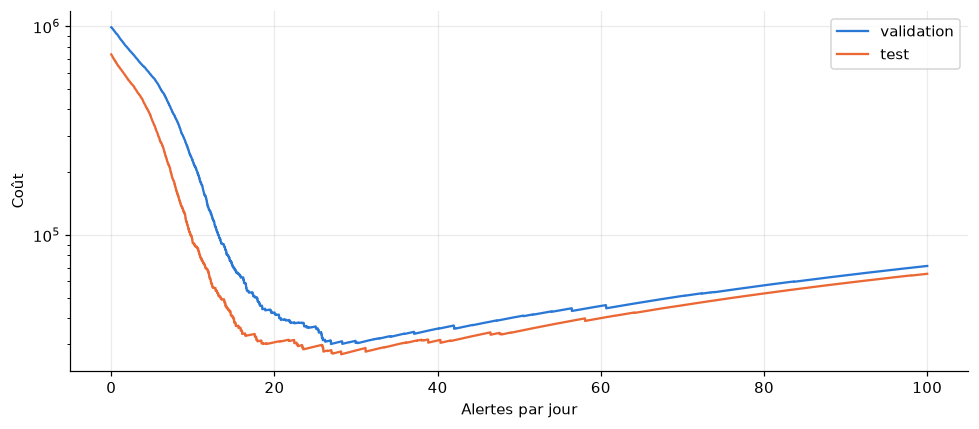

In [6]:
fig, ax = plt.subplots(figsize=(9, 4))
for nom, couleur in (("validation", BLEU), ("test", ORANGE)):
    sous = evaluation.courbe_cout_selon_alertes(jeux[nom], "xgboost")
    sous = sous[sous["alertes_par_jour"] <= 100]
    ax.plot(sous["alertes_par_jour"], sous["cout"], color=couleur, label=nom)
ax.set_yscale("log")
ax.set_xlabel("Alertes par jour")
ax.set_ylabel("Coût")
ax.legend()
fig.tight_layout()

## Confirmation sur le test

In [7]:
seuil = choix["seuil"]
lignes = [evaluation.evaluer_au_seuil(jeu, "xgboost", seuil, COUT_ALERTE, ALERTES_PAR_JOUR) | {"jeu": nom} for nom, jeu in jeux.items()]
confirmation = pd.DataFrame(lignes).set_index("jeu")
confirmation[["alertes", "vp", "fp", "fn", "precision", "rappel", "f2", "mcc", "cout", "cout_sans_modele", "economie"]]

,alertes,vp,fp,fn,precision,rappel,f2,mcc,cout,cout_sans_modele,economie
jeu,,,,,,,,,,,
validation,3763,1819,1944,82,0.4834,0.9569,0.8001,0.6781,"30,109.1100","989,313.4600",0.9696
test,3144,1283,1861,66,0.4081,0.9511,0.7512,0.6212,"28,907.5400","733,911.7200",0.9606


In [8]:
y = test["is_fraud"].to_numpy()
optimal_test = metriques.seuil_optimal(y, test["xgboost"].to_numpy(), test["amt"].to_numpy(), COUT_ALERTE)
{"cout_au_seuil_de_la_validation": confirmation.loc["test", "cout"], "cout_au_seuil_optimal_du_test": optimal_test["cout"]}

{'cout_au_seuil_de_la_validation': np.float64(28907.54),
 'cout_au_seuil_optimal_du_test': 26879.749999999534}

## Sensibilité au coût d'analyse

In [9]:
sensibilite = pd.read_csv(RACINE / "resultats" / "sensibilite_cout.csv")
sensibilite[sensibilite["methode"] == "xgboost"][["cout_alerte", "seuil", "alertes_test", "rappel_test", "precision_test", "cout_test", "economie_test"]]

,cout_alerte,seuil,alertes_test,rappel_test,precision_test,cout_test,economie_test
0,1.0000,0.0033,7612,0.9785,0.1734,"9,007.9300",0.9877
1,2.0000,0.0193,3573,0.9577,0.3616,"16,724.6100",0.9772
2,5.0000,0.0272,3144,0.9511,0.4081,"28,907.5400",0.9606
3,10.0000,0.0272,3144,0.9511,0.4081,"44,627.5400",0.9392
4,20.0000,0.0656,2322,0.9318,0.5413,"65,893.6500",0.9102
5,50.0000,0.1440,1812,0.8999,0.6700,"127,096.6600",0.8268


In [10]:
budgets = pd.read_csv(RACINE / "resultats" / "evaluation_selon_budget.csv")
sous = budgets[budgets["methode"].isin(["xgboost", "logistique", "isolation_forest"])]
sous.head(12)

,jeu,alertes_par_jour,k,methode,precision_a_k,rappel_a_k
0,validation,5,699,xgboost,0.9986,0.3672
1,validation,5,699,logistique,0.7954,0.2925
2,validation,5,699,isolation_forest,0.2647,0.0973
6,validation,10,1398,xgboost,0.9564,0.7033
7,validation,10,1398,logistique,0.5894,0.4335
8,validation,10,1398,isolation_forest,0.2260,0.1662
12,validation,15,2097,xgboost,0.7892,0.8706
13,validation,15,2097,logistique,0.4578,0.5050
14,validation,15,2097,isolation_forest,0.2127,0.2346
18,validation,20,2795,xgboost,0.6283,0.9237


## Lecture

Le seuil optimal dépend du coût d'analyse : plus l'analyse d'une alerte coûte cher, moins il y a d'alertes et plus les petites fraudes passent. L'application permet de faire varier ce coût et le budget en direct.